In [41]:
import pandas as pd
import numpy as np


orders = pd.read_csv('olist_orders_dataset.csv')
items = pd.read_csv('olist_order_items_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
category_translation = pd.read_csv('product_category_name_translation.csv')

In [42]:
df = pd.merge(orders, items, on='order_id', how='left')
df.head()



,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1.0,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1.0,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1.0,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1.0,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1.0,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [23]:
#merge product dimensions to dataframe
df = pd.merge(df, products, on='product_id', how='left')
df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1.0,87285b34884572647811a353c7ac498a,...,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1.0,595fac2a385ac33a80bd5114aec74eb8,...,118.70,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1.0,aa4383b373c6aca5d8797843e5594415,...,159.90,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1.0,d0b61bfb1de832b15ba9d266ca96e5b0,...,45.00,27.20,pet_shop,59.0,468.0,3.0,450.0,30.0,10.0,20.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1.0,65266b2da20d04dbe00c5c2d3bb7859e,...,19.90,8.72,papelaria,38.0,316.0,4.0,250.0,51.0,15.0,15.0


In [24]:
category_translation.head()
df = pd.merge(df,category_translation, on="product_category_name", how= "left")
df.head()
# english translation of products

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1.0,87285b34884572647811a353c7ac498a,...,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0,housewares
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1.0,595fac2a385ac33a80bd5114aec74eb8,...,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1.0,aa4383b373c6aca5d8797843e5594415,...,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1.0,d0b61bfb1de832b15ba9d266ca96e5b0,...,27.20,pet_shop,59.0,468.0,3.0,450.0,30.0,10.0,20.0,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1.0,65266b2da20d04dbe00c5c2d3bb7859e,...,8.72,papelaria,38.0,316.0,4.0,250.0,51.0,15.0,15.0,stationery


In [25]:

# Join the Customers table using 'customer_id'
df = pd.merge(df, customers, on='customer_id', how='left')
df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1.0,87285b34884572647811a353c7ac498a,...,4.0,500.0,19.0,8.0,13.0,housewares,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1.0,595fac2a385ac33a80bd5114aec74eb8,...,1.0,400.0,19.0,13.0,19.0,perfumery,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1.0,aa4383b373c6aca5d8797843e5594415,...,1.0,420.0,24.0,19.0,21.0,auto,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1.0,d0b61bfb1de832b15ba9d266ca96e5b0,...,3.0,450.0,30.0,10.0,20.0,pet_shop,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1.0,65266b2da20d04dbe00c5c2d3bb7859e,...,4.0,250.0,51.0,15.0,15.0,stationery,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP


In [26]:
# Join the Payments table using 'order_id'

df = pd.merge(df, payments, on='order_id', how='left')
df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,product_width_cm,product_category_name_english,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,payment_sequential,payment_type,payment_installments,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1.0,87285b34884572647811a353c7ac498a,...,13.0,housewares,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1.0,credit_card,1.0,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1.0,87285b34884572647811a353c7ac498a,...,13.0,housewares,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,3.0,voucher,1.0,2.00
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1.0,87285b34884572647811a353c7ac498a,...,13.0,housewares,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,2.0,voucher,1.0,18.59
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1.0,595fac2a385ac33a80bd5114aec74eb8,...,19.0,perfumery,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1.0,boleto,1.0,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1.0,aa4383b373c6aca5d8797843e5594415,...,21.0,auto,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1.0,credit_card,3.0,179.12


In [27]:
 
# Join the Sellers table using 'seller_id'
df = pd.merge(df, sellers, on='seller_id', how='left')

In [28]:
print(f"Number of rows and columns: {df.shape}")
print(df.head())

Number of rows and columns: (118434, 34)
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
2  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
3  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
4  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
2    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
3    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
4    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1      

In [29]:
total_orders = df['order_id'].nunique()

In [30]:
date_columns = [
    'order_purchase_timestamp', 
    'order_delivered_carrier_date', 
    'order_delivered_customer_date', 
    'order_estimated_delivery_date', 
    'shipping_limit_date'
]

# Loop through and convert them to proper datetime objects
for col in date_columns:
    df[col] = pd.to_datetime(df[col])

print("Dates converted successfully!")

# Instead of deleting rows with missing categories, let's fill the blanks with "Unknown"
df['product_category_name_english'] = df['product_category_name_english'].fillna('Unknown')



#fill it with the median (middle) weight of all products.
median_weight = df['product_weight_g'].median()
df['product_weight_g'] = df['product_weight_g'].fillna(median_weight)


print(f"Missing categories now: {df['product_category_name_english'].isnull().sum()}")

Dates converted successfully!
Missing categories now: 0


C:\Users\Dylan\AppData\Local\Temp\ipykernel_15328\3954309198.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='revenue_millions', y='product_category_name_english', data=top_10_revenue, palette='mako' )


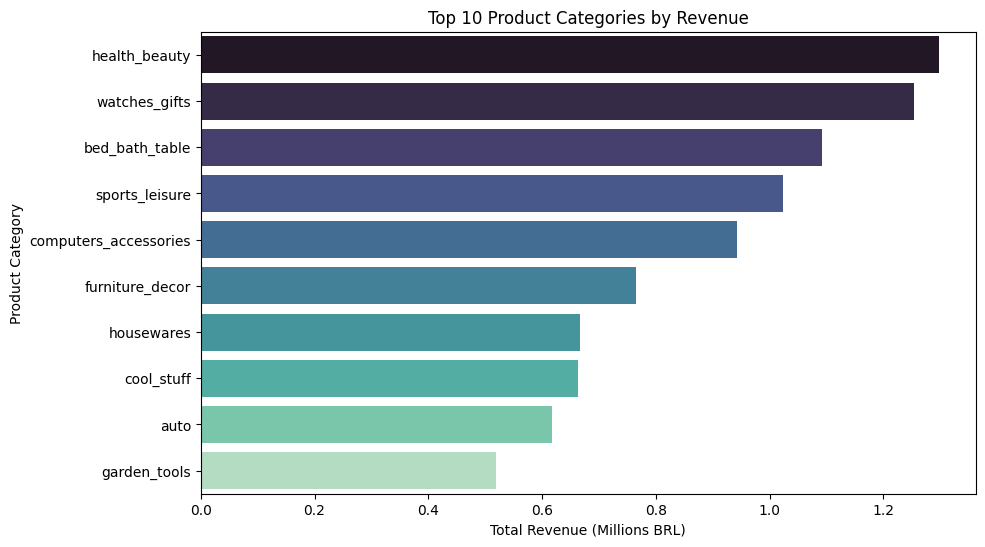

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group the data by category and sum the prices
revenue_by_category = df.groupby('product_category_name_english')['price'].sum().reset_index()

# 2. Sort the values from highest to lowest and grab the top 10
top_10_revenue = revenue_by_category.sort_values(by='price', ascending=False).head(10)

# 3. Create a quick visual (dividing by 1 million for cleaner chart labels)
top_10_revenue['revenue_millions'] = top_10_revenue['price'] / 1000000

plt.figure(figsize=(10, 6))
sns.barplot(x='revenue_millions', y='product_category_name_english', data=top_10_revenue, palette='mako' )
plt.title('Top 10 Product Categories by Revenue')
plt.xlabel('Total Revenue (Millions BRL)')
plt.ylabel('Product Category')
plt.show()

C:\Users\Dylan\AppData\Local\Temp\ipykernel_15328\2231144979.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='total_items_sold', y='product_category_name_english', data=top_10_volume, palette='viridis')


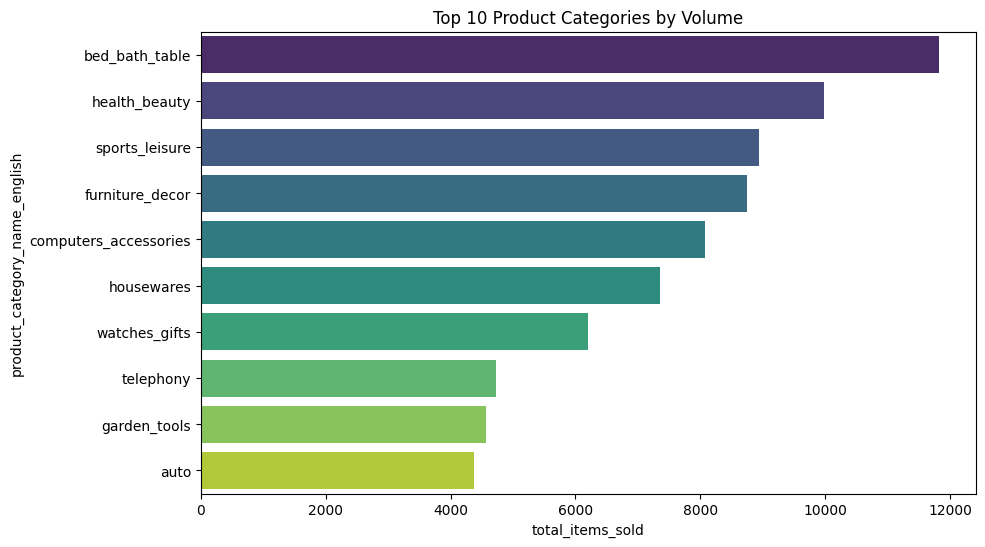

In [32]:
# 1. Calculate Volume (count of items sold)
volume_by_category = df.groupby('product_category_name_english')['product_id'].count().reset_index()
volume_by_category.columns = ['product_category_name_english', 'total_items_sold']

# 2. Calculate Average Price
avg_price_by_category = df.groupby('product_category_name_english')['price'].mean().reset_index()
avg_price_by_category.columns = ['product_category_name_english', 'average_price']

# 3. Merge them to get the full picture
category_stats = pd.merge(volume_by_category, avg_price_by_category, on='product_category_name_english')

# 4. Sort to find Top 10 by Volume
top_10_volume = category_stats.sort_values(by='total_items_sold', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='total_items_sold', y='product_category_name_english', data=top_10_volume, palette='viridis')
plt.title('Top 10 Product Categories by Volume')
plt.show()

C:\Users\Dylan\AppData\Local\Temp\ipykernel_15328\1717514371.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='customer_state', y='unique_customers', data=top_states, palette='crest')


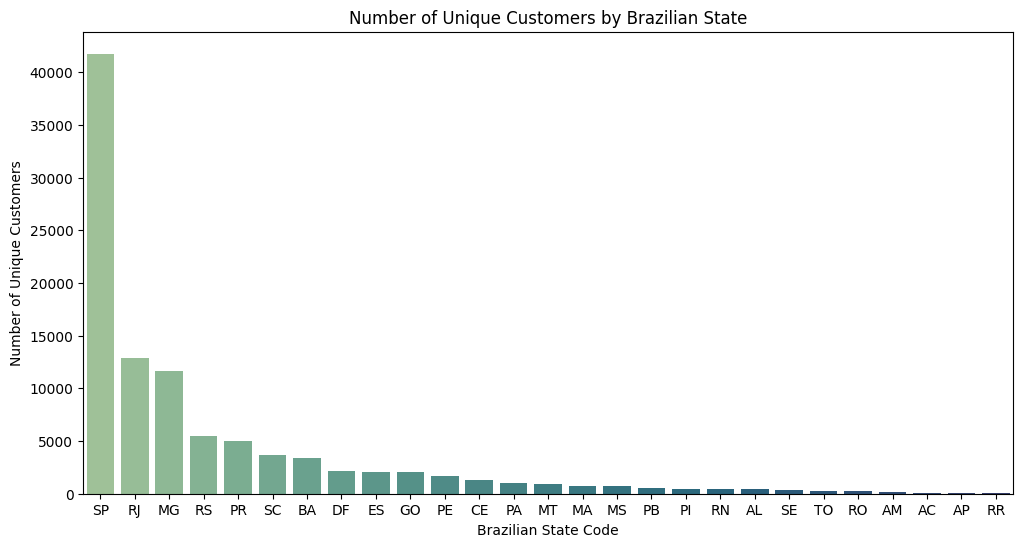

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Group by State and count unique customers
customers_by_state = df.groupby('customer_state')['customer_id'].nunique().reset_index()
customers_by_state.columns = ['customer_state', 'unique_customers']

# 2. Sort the states from highest to lowest
top_states = customers_by_state.sort_values(by='unique_customers', ascending=False)

# 3. Visualize
plt.figure(figsize=(12, 6))
sns.barplot(x='customer_state', y='unique_customers', data=top_states, palette='crest')
plt.title('Number of Unique Customers by Brazilian State')
plt.xlabel('Brazilian State Code')
plt.ylabel('Number of Unique Customers')
plt.show()

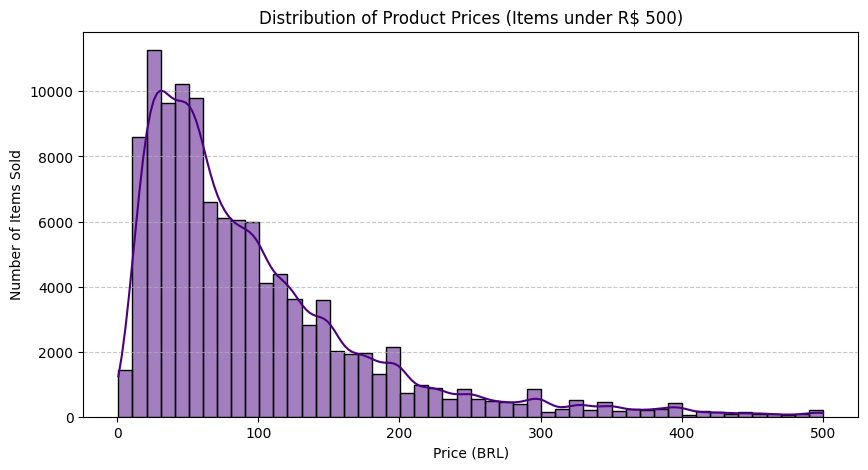

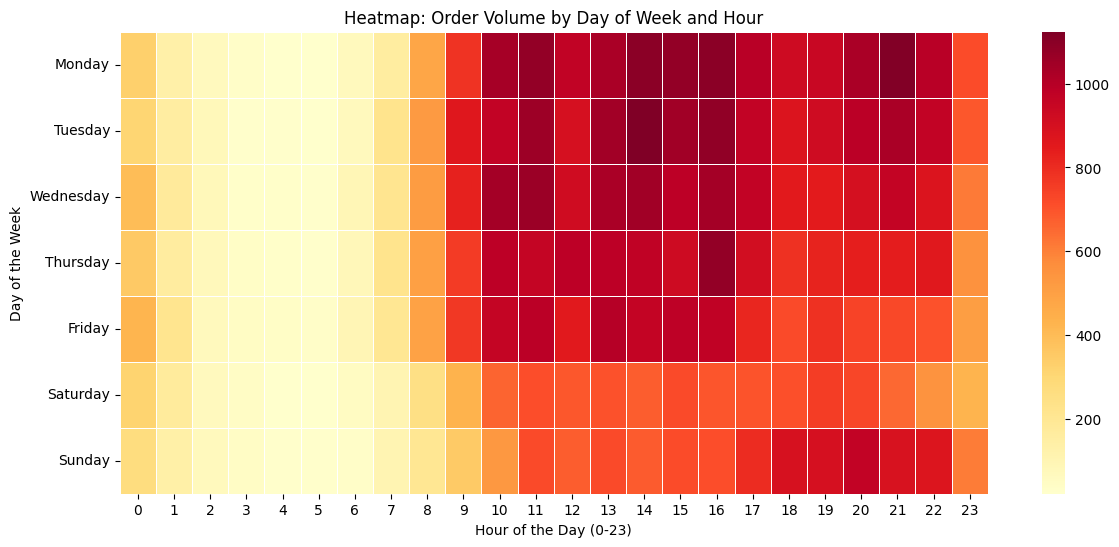

In [34]:

# Load the dataset and ensure timestamps are treated as dates
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# --- 1. HISTOGRAM: Price Distribution ---
plt.figure(figsize=(10, 5))

# We filter to items under 500 BRL to avoid massive outliers ruining the scale
sns.histplot(df[df['price'] < 500]['price'], bins=50, color='indigo', kde=True)

plt.title('Distribution of Product Prices (Items under R$ 500)')
plt.xlabel('Price (BRL)')
plt.ylabel('Number of Items Sold')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


# Extract the Day of the Week and the Hour of the Day from the timestamp
df['day_of_week'] = df['order_purchase_timestamp'].dt.day_name()
df['hour'] = df['order_purchase_timestamp'].dt.hour

# Group by Day and Hour to get the count of unique orders
heatmap_data = df.groupby(['day_of_week', 'hour'])['order_id'].nunique().reset_index()

# Pivot the data into a matrix format (Rows = Days, Columns = Hours)
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_pivot = heatmap_data.pivot(index='day_of_week', columns='hour', values='order_id').reindex(days_order)

plt.figure(figsize=(14, 6))
sns.heatmap(heatmap_pivot, cmap='YlOrRd', linewidths=0.5)

plt.title('Heatmap: Order Volume by Day of Week and Hour')
plt.xlabel('Hour of the Day (0-23)')
plt.ylabel('Day of the Week')
plt.yticks(rotation=0) 
plt.show()

In [35]:
df.to_csv('merged_olist_data.csv', index=False)

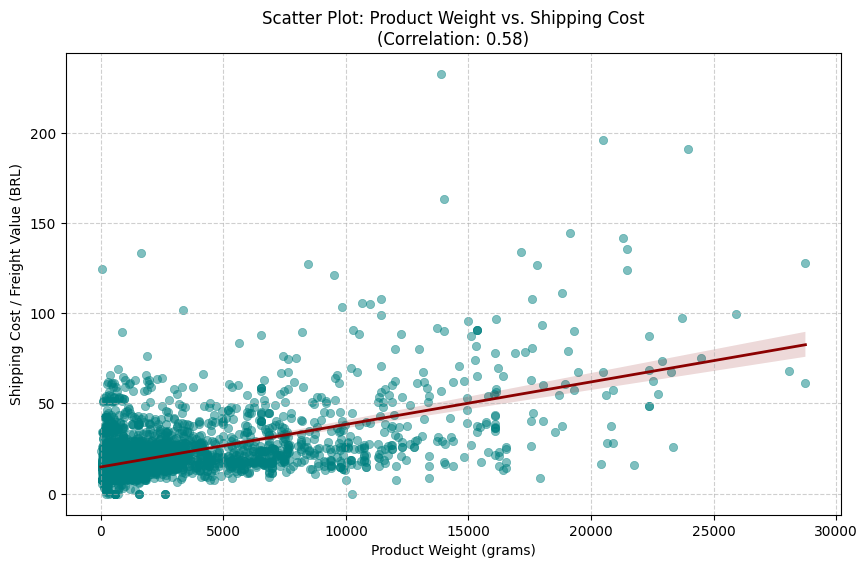

In [36]:

df = pd.read_csv('merged_olist_data.csv')

plt.figure(figsize=(10, 6))


sample_df = df[(df['product_weight_g'] < 30000) & (df['freight_value'] < 300)].dropna(subset=['product_weight_g', 'freight_value'])


correlation = sample_df['product_weight_g'].corr(sample_df['freight_value'])


plot_df = sample_df.sample(5000, random_state=42)


sns.scatterplot(data=plot_df, x='product_weight_g', y='freight_value', alpha=0.5, color='teal', edgecolor=None)


sns.regplot(data=plot_df, x='product_weight_g', y='freight_value', scatter=False, color='darkred', line_kws={"linewidth": 2})


plt.title(f'Scatter Plot: Product Weight vs. Shipping Cost\n(Correlation: {correlation:.2f})')
plt.xlabel('Product Weight (grams)')
plt.ylabel('Shipping Cost / Freight Value (BRL)')
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

In [37]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.preprocessing import StandardScaler


df = pd.read_csv('merged_olist_data.csv')
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df['order_delivered_customer_date'] = pd.to_datetime(df['order_delivered_customer_date'])

print("--- ML PIPELINE RESULTS ---\n")


reviews = pd.read_csv('olist_order_reviews_dataset.csv')
df_rev = pd.merge(df, reviews[['order_id', 'review_score']], on='order_id', how='inner')

# Create binary target: 1 if score >= 4 (Happy), 0 if < 4 (Unhappy)
df_rev['is_happy'] = (df_rev['review_score'] >= 4).astype(int)


df_rev['delivery_days'] = (df_rev['order_delivered_customer_date'] - df_rev['order_purchase_timestamp']).dt.days


ml_df = df_rev[['price', 'freight_value', 'product_weight_g', 'delivery_days', 'is_happy']].dropna()


X_clf = ml_df[['price', 'freight_value', 'product_weight_g', 'delivery_days']]
y_clf = ml_df['is_happy']
X_train, X_test, y_train, y_test = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42)

rf = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
acc = accuracy_score(y_test, rf.predict(X_test))

print(f"1. Classification (Random Forest)")
print(f"   Accuracy in predicting Happy vs. Unhappy customers: {acc:.2%}")
importance = rf.feature_importances_
top_feature = X_clf.columns[np.argmax(importance)]
print(f"   The algorithm found that '{top_feature}' is the #1 predictor of a bad review.\n")



# Recency, Frequency, Monetary
max_date = df['order_purchase_timestamp'].max()
rfm = df.groupby('customer_id').agg({
    'order_purchase_timestamp': lambda x: (max_date - x.max()).days, # Recency
    'order_id': 'nunique', # Frequency
    'price': 'sum' # Monetary
}).reset_index()
rfm.columns = ['customer_id', 'Recency', 'Frequency', 'Monetary']


scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[['Recency', 'Frequency', 'Monetary']])
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

print(f"2. Clustering (K-Means)")
print(f"   Successfully grouped {len(rfm):,} unique customers into 4 behavioral segments.")

best_cluster = rfm.groupby('Cluster')['Monetary'].mean().idxmax()
print(f"   Cluster {best_cluster} represents your 'VIP Whales' (highest average spend).\n")


# --- 3. REGRESSION: Delivery Time Estimation ---
X_reg = ml_df[['price', 'freight_value', 'product_weight_g']]
y_reg = ml_df['delivery_days']

Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)
lr = LinearRegression()
lr.fit(Xr_train, yr_train)
preds = lr.predict(Xr_test)
rmse = np.sqrt(mean_squared_error(yr_test, preds))

print(f"3. Regression (Linear Regression)")
print(f"   Model Error (RMSE): It is off by an average of {rmse:.2f} days when predicting delivery.")

--- ML PIPELINE RESULTS ---

1. Classification (Random Forest)
   Accuracy in predicting Happy vs. Unhappy customers: 79.31%
   The algorithm found that 'delivery_days' is the #1 predictor of a bad review.

2. Clustering (K-Means)
   Successfully grouped 99,441 unique customers into 4 behavioral segments.
   Cluster 2 represents your 'VIP Whales' (highest average spend).

3. Regression (Linear Regression)
   Model Error (RMSE): It is off by an average of 9.08 days when predicting delivery.


In [38]:

from sklearn.metrics import mean_squared_error
from sklearn.ensemble import GradientBoostingRegressor


df = pd.read_csv('merged_olist_data.csv')


df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df['order_delivered_customer_date'] = pd.to_datetime(df['order_delivered_customer_date'])
df['delivery_days'] = (df['order_delivered_customer_date'] - df['order_purchase_timestamp']).dt.days


ml_df = df[['price', 'freight_value', 'product_weight_g', 'delivery_days']].dropna()

X = ml_df[['price', 'freight_value', 'product_weight_g']]
y = ml_df['delivery_days']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


gbr_model = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42)


print("Training the boosting model (this might take a few seconds)...")
gbr_model.fit(X_train, y_train)


predictions = gbr_model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print(f"Gradient Boosting Error (RMSE): {rmse:.2f} days")

Training the boosting model (this might take a few seconds)...
Gradient Boosting Error (RMSE): 8.68 days


In [43]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import GradientBoostingRegressor

df = pd.read_csv('merged_olist_data.csv')
geo = pd.read_csv('olist_geolocation_dataset.csv')

# Fix the "Row Explosion" problem by averaging coordinates per zip code
geo_grouped = geo.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].mean().reset_index()

# Join Coordinates for the Buyer
df = pd.merge(df, geo_grouped, left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left')
df.rename(columns={'geolocation_lat': 'buyer_lat', 'geolocation_lng': 'buyer_lng'}, inplace=True)

#  Join Coordinates for the Seller
df = pd.merge(df, geo_grouped, left_on='seller_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left')
df.rename(columns={'geolocation_lat': 'seller_lat', 'geolocation_lng': 'seller_lng'}, inplace=True)

 #Math: The Haversine Formula to calculate kilometers
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371 
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    return R * c

#  Create the new distance feature
df['distance_km'] = haversine_distance(df['buyer_lat'], df['buyer_lng'], df['seller_lat'], df['seller_lng'])

# Calculate actual delivery days
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df['order_delivered_customer_date'] = pd.to_datetime(df['order_delivered_customer_date'])
df['delivery_days'] = (df['order_delivered_customer_date'] - df['order_purchase_timestamp']).dt.days


ml_df = df[['price', 'freight_value', 'product_weight_g', 'distance_km', 'delivery_days']].dropna()

X = ml_df[['price', 'freight_value', 'product_weight_g', 'distance_km']]
y = ml_df['delivery_days']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


gbr = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42)
gbr.fit(X_train, y_train)


preds = gbr.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, preds))

print(f"New Model Error (RMSE): {rmse:.2f} days")

New Model Error (RMSE): 8.17 days


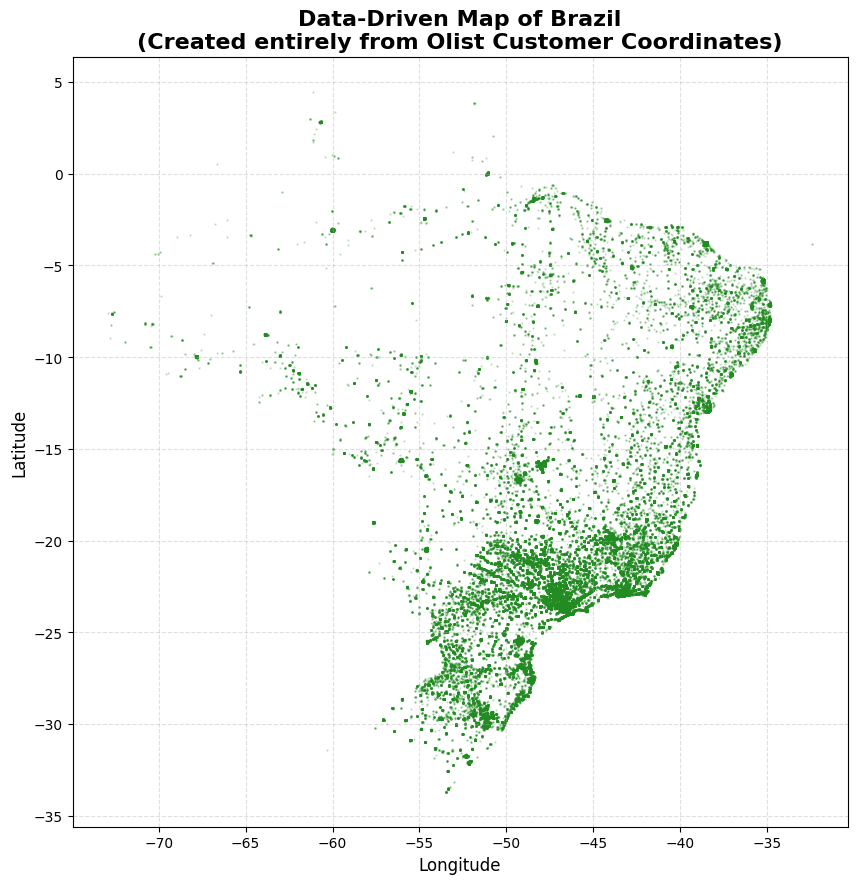

In [40]:
import pandas as pd
import matplotlib.pyplot as plt


geo = pd.read_csv('olist_geolocation_dataset.csv')


# filter to Brazil's rough bounding box
brazil_geo = geo[(geo['geolocation_lat'] <= 5) & 
                 (geo['geolocation_lat'] >= -35) & 
                 (geo['geolocation_lng'] <= -30) & 
                 (geo['geolocation_lng'] >= -75)]


sample_geo = brazil_geo.sample(300000, random_state=42)


plt.figure(figsize=(10, 10))


plt.scatter(sample_geo['geolocation_lng'], sample_geo['geolocation_lat'], 
            s=0.5, alpha=0.2, color='forestgreen')

plt.title('Data-Driven Map of Brazil\n(Created entirely from Olist Customer Coordinates)', fontsize=16, fontweight='bold')
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.4)
plt.savefig("my_graph.png", dpi=300, bbox_inches='tight')
plt.show()